## Chatper 2 Exercises

In [2]:
USE TSQLV6

Commands completed successfully.

Total execution time: 00:00:00.006

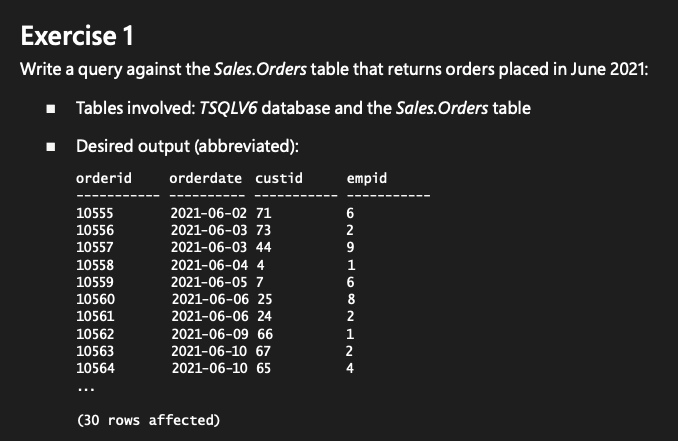

In [3]:
SELECT orderid, orderdate, custid, empid
FROM Sales.Orders
WHERE orderdate >= '20210601' AND orderdate < '20210701';

(30 rows affected)

orderid | orderdate  | custid | empid
--------+------------+--------+------
10555   | 2021-06-02 | 71     | 6    
10556   | 2021-06-03 | 73     | 2    
10557   | 2021-06-03 | 44     | 9    
10558   | 2021-06-04 | 4      | 1    
10559   | 2021-06-05 | 7      | 6    
10560   | 2021-06-06 | 25     | 8    
10561   | 2021-06-06 | 24     | 2    
10562   | 2021-06-09 | 66     | 1    
10563   | 2021-06-10 | 67     | 2    
10564   | 2021-06-10 | 65     | 4    
10565   | 2021-06-11 | 51     | 8    
10566   | 2021-06-12 | 7      | 9    
10567   | 2021-06-12 | 37     | 1    
10568   | 2021-06-13 | 29     | 3    
10569   | 2021-06-16 | 65     | 5    
10570   | 2021-06-17 | 51     | 3    
10571   | 2021-06-17 | 20     | 8    
10572   | 2021-06-18 | 5      | 3    
10573   | 2021-06-19 | 3      | 7    
10574   | 2021-06-19 | 82     | 4    
10575   | 2021-06-20 | 52     | 5    
10576   | 2021-06-23 | 80     | 3    
10577   | 2021-06-23 | 82     | 9    
10578   | 2021-06-24 | 11     

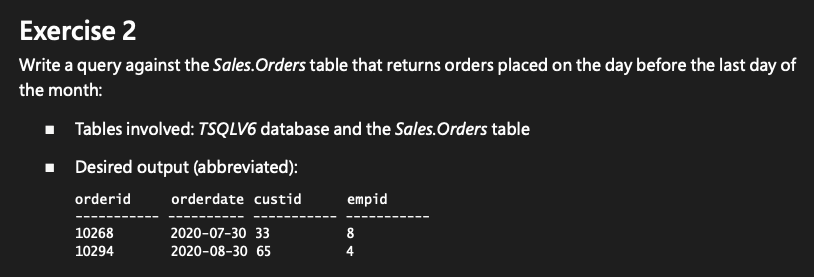
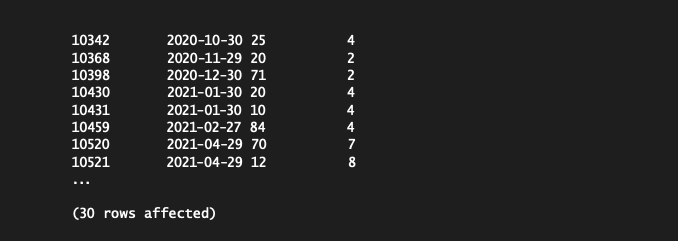

In [4]:
SELECT orderid, orderdate, custid, empid, EOMONTH(orderdate)
FROM Sales.Orders
-- WHERE DATEPART(day, orderdate) = 1;
WHERE DATEDIFF(day, orderdate, DATEADD(day, -1, EOMONTH(orderdate))) = 0;

(30 rows affected)

orderid | orderdate  | custid | empid | (No column name)
--------+------------+--------+-------+-----------------
10268   | 2020-07-30 | 33     | 8     | 2020-07-31      
10294   | 2020-08-30 | 65     | 4     | 2020-08-31      
10342   | 2020-10-30 | 25     | 4     | 2020-10-31      
10368   | 2020-11-29 | 20     | 2     | 2020-11-30      
10398   | 2020-12-30 | 71     | 2     | 2020-12-31      
10430   | 2021-01-30 | 20     | 4     | 2021-01-31      
10431   | 2021-01-30 | 10     | 4     | 2021-01-31      
10459   | 2021-02-27 | 84     | 4     | 2021-02-28      
10520   | 2021-04-29 | 70     | 7     | 2021-04-30      
10521   | 2021-04-29 | 12     | 8     | 2021-04-30      
10553   | 2021-05-30 | 87     | 2     | 2021-05-31      
10554   | 2021-05-30 | 56     | 4     | 2021-05-31      
10615   | 2021-07-30 | 90     | 2     | 2021-07-31      
10685   | 2021-09-29 | 31     | 4     | 2021-09-30      
10723   | 2021-10-30 | 89     | 3     | 2021-10-31      
10724   | 2

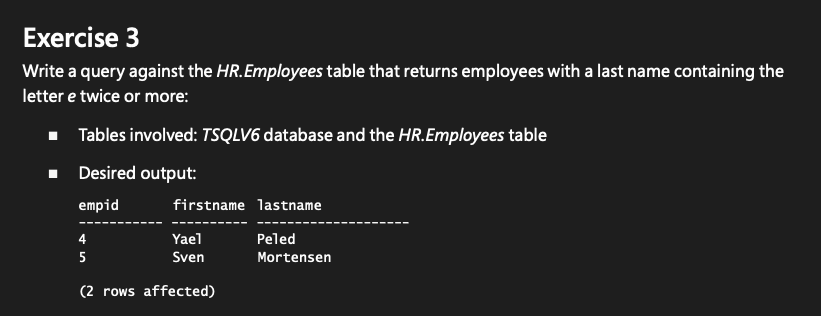

In [5]:
SELECT empid, firstname, lastname
FROM HR.Employees
WHERE LEN(lastname) - LEN(REPLACE(lastname, 'e', '')) >= 2;

(2 rows affected)

empid | firstname | lastname 
------+-----------+----------
4     | Yael      | Peled    
5     | Sven      | Mortensen
(2 rows)

Total execution time: 00:00:00.022

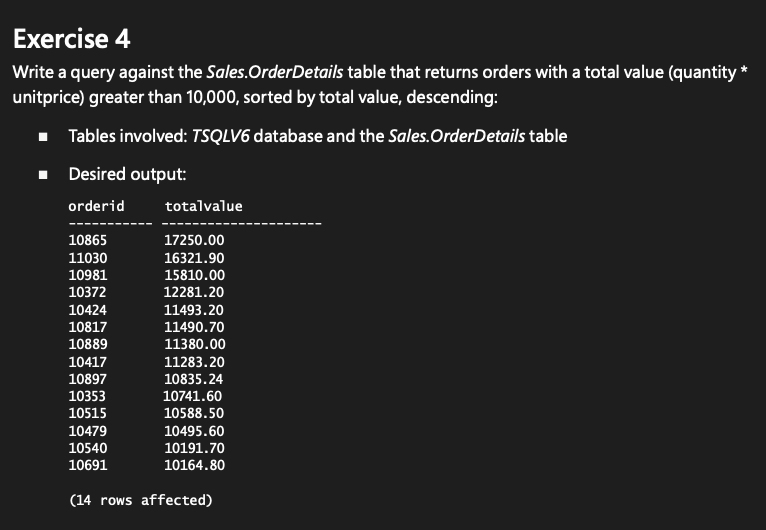

In [6]:
SELECT orderid, (qty * unitprice) AS totalvalue
FROM Sales.OrderDetails
WHERE (qty * unitprice) > 10000
ORDER BY totalvalue;

(6 rows affected)

orderid | totalvalue
--------+-----------
10424   | 10329.20  
10353   | 10540.00  
10417   | 10540.00  
10889   | 10540.00  
10981   | 15810.00  
10865   | 15810.00  
(6 rows)

Total execution time: 00:00:00.056

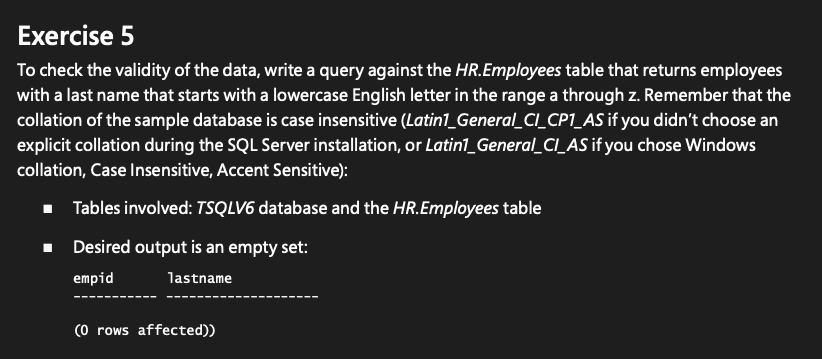

In [11]:
SELECT empid, lastname
FROM HR.Employees
-- WHERE lastname COLLATE Latin1_General_CS_AS LIKE N'[a-z]%'; -- regular dictionary order groups upper and lower in range, so aAbBcC...zZ, need to separate a..z,A..Z
-- WHERE lastname COLLATE Latin1_General_100_BIN2 LIKE N'[a-z]%';
WHERE lastname COLLATE Latin1_General_BIN LIKE N'[a-z]%';

(0 rows affected)

(0 rows)

Total execution time: 00:00:00.003

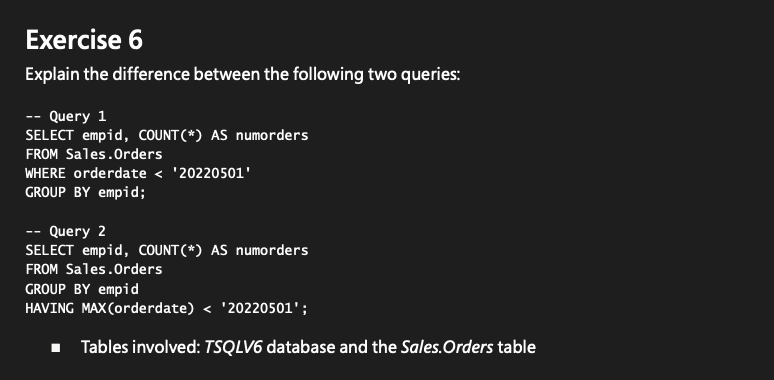
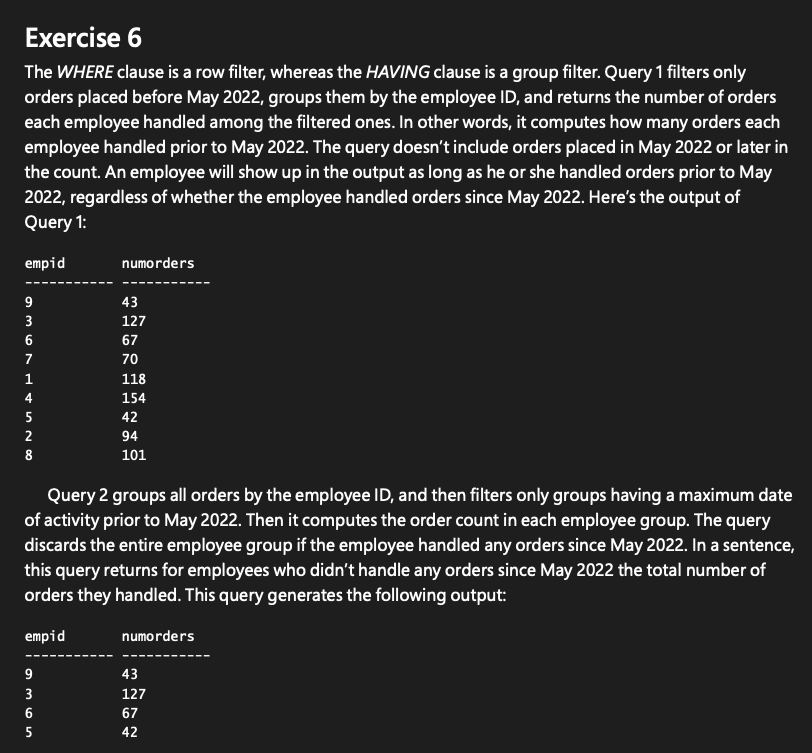
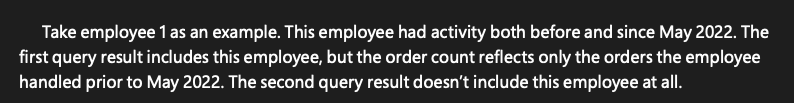

In [ ]:
SELECT empid, COUNT(*) AS numorders
FROM Sales.Orders
WHERE orderdate < '20220501'
GROUP BY empid;

SELECT empid, COUNT(*) AS numorders
FROM Sales.Orders
GROUP BY empid
HAVING MAX(orderdate) < '20220501';

(9 rows affected)
(4 rows affected)

empid | numorders
------+----------
9     | 43       
3     | 127      
6     | 67       
7     | 70       
1     | 118      
4     | 154      
5     | 42       
2     | 94       
8     | 101      
(9 rows)

empid | numorders
------+----------
9     | 43       
3     | 127      
6     | 67       
5     | 42       
(4 rows)

Total execution time: 00:00:00.101

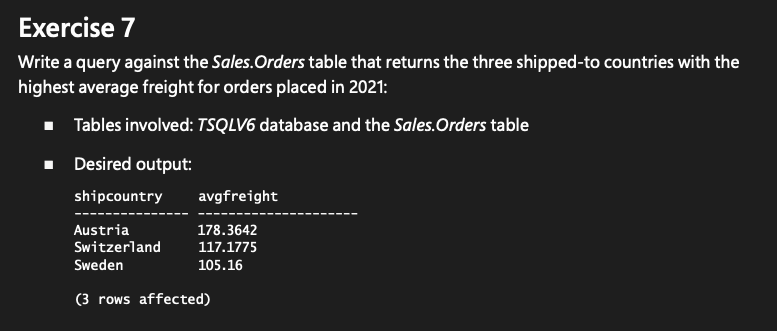

In [15]:
SELECT TOP 3 shipcountry, AVG(freight) AS avgfreight
FROM Sales.Orders
-- WHERE YEAR(orderdate) = '2021'
WHERE orderdate >= '20210101' AND orderdate < '20220101'
GROUP BY shipcountry
ORDER BY AVG(freight) DESC;

(3 rows affected)

shipcountry | avgfreight
------------+-----------
Austria     | 178.3642  
Switzerland | 117.1775  
Sweden      | 105.16    
(3 rows)

Total execution time: 00:00:00.027

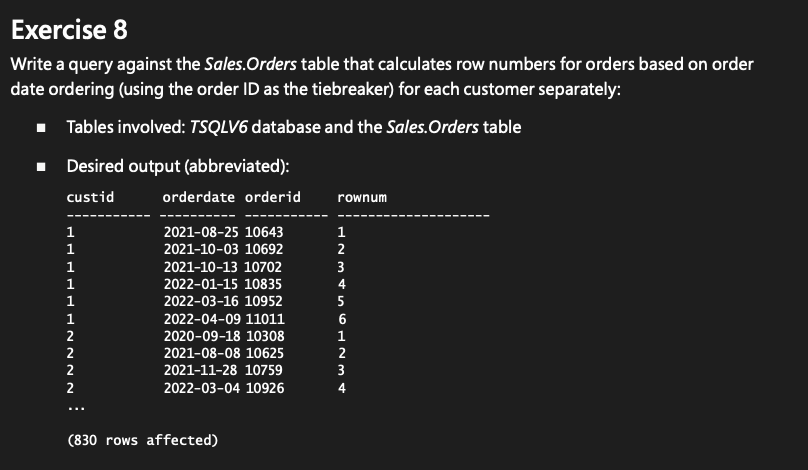

In [18]:
SELECT custid, orderdate, orderid,
  ROW_NUMBER() OVER(PARTITION BY custid ORDER BY orderdate, orderid) AS rownum
FROM Sales.Orders
ORDER BY custid, rownum

(830 rows affected)

custid | orderdate  | orderid | rownum
-------+------------+---------+-------
1      | 2021-08-25 | 10643   | 1     
1      | 2021-10-03 | 10692   | 2     
1      | 2021-10-13 | 10702   | 3     
1      | 2022-01-15 | 10835   | 4     
1      | 2022-03-16 | 10952   | 5     
1      | 2022-04-09 | 11011   | 6     
2      | 2020-09-18 | 10308   | 1     
2      | 2021-08-08 | 10625   | 2     
2      | 2021-11-28 | 10759   | 3     
2      | 2022-03-04 | 10926   | 4     
3      | 2020-11-27 | 10365   | 1     
3      | 2021-04-15 | 10507   | 2     
3      | 2021-05-13 | 10535   | 3     
3      | 2021-06-19 | 10573   | 4     
3      | 2021-09-22 | 10677   | 5     
3      | 2021-09-25 | 10682   | 6     
3      | 2022-01-28 | 10856   | 7     
4      | 2020-11-15 | 10355   | 1     
4      | 2020-12-16 | 10383   | 2     
4      | 2021-02-21 | 10453   | 3     
4      | 2021-06-04 | 10558   | 4     
4      | 2021-10-16 | 10707   | 5     
4      | 2021-11-14 | 10741   | 6     
4   

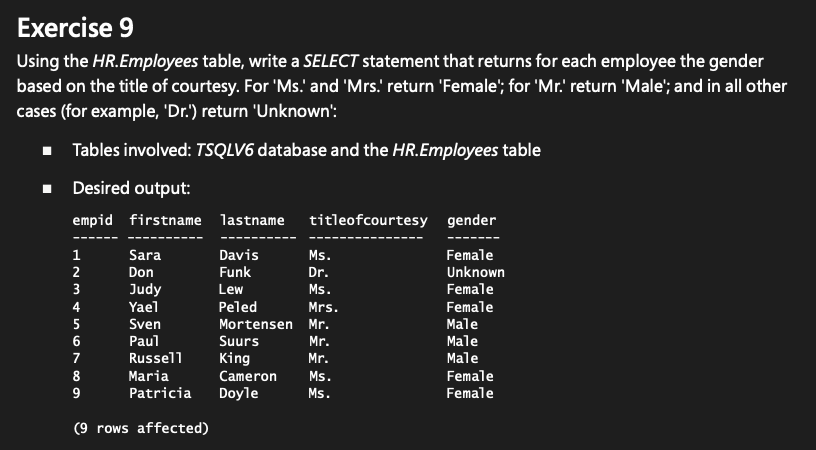

In [21]:
SELECT empid, firstname, lastname, titleofcourtesy,
  CASE
    -- WHEN titleofcourtesy = 'Ms.' OR titleofcourtesy = 'Mrs.' THEN 'Female'
    WHEN titleofcourtesy IN ('Ms.', 'Mrs.') THEN 'Female'
    WHEN titleofcourtesy = 'Mr.' THEN 'Male'
    ELSE 'unknown'
  END AS gender
FROM HR.Employees

(9 rows affected)

empid | firstname | lastname  | titleofcourtesy | gender 
------+-----------+-----------+-----------------+--------
1     | Sara      | Davis     | Ms.             | Female 
2     | Don       | Funk      | Dr.             | unknown
3     | Judy      | Lew       | Ms.             | Female 
4     | Yael      | Peled     | Mrs.            | Female 
5     | Sven      | Mortensen | Mr.             | Male   
6     | Paul      | Suurs     | Mr.             | Male   
7     | Russell   | King      | Mr.             | Male   
8     | Maria     | Cameron   | Ms.             | Female 
9     | Patricia  | Doyle     | Ms.             | Female 
(9 rows)

Total execution time: 00:00:00.007

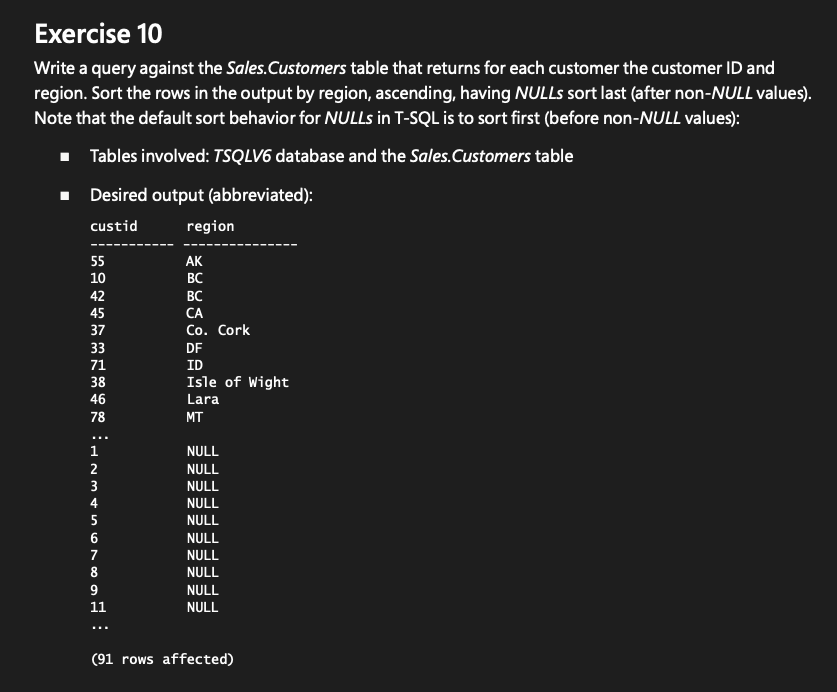

In [23]:
SELECT custid, region
FROM Sales.Customers
ORDER BY CASE WHEN region IS NULL THEN 1 ELSE 0 END, region;

(91 rows affected)

custid | region       
-------+--------------
55     | AK           
10     | BC           
42     | BC           
45     | CA           
37     | Co. Cork     
33     | DF           
71     | ID           
38     | Isle of Wight
46     | Lara         
78     | MT           
65     | NM           
47     | Nueva Esparta
32     | OR           
36     | OR           
48     | OR           
77     | OR           
51     | Québec       
34     | RJ           
61     | RJ           
67     | RJ           
15     | SP           
21     | SP           
31     | SP           
62     | SP           
81     | SP           
88     | SP           
35     | Táchira      
43     | WA           
82     | WA           
89     | WA           
75     | WY           
1      | NULL         
2      | NULL         
3      | NULL         
4      | NULL         
5      | NULL         
6      | NULL         
7      | NULL         
8      | NULL         
9      | NULL         
11     | NULL 